<div style="text-align:right">
<img src="imgs/logo-curso.jpg" width="30%" style="max-width:100%; padding-right:20px;">
</div>

**Fundamentos de la Inteligencia Artificial y Programación de APIs para LLMs**

# **06. Redes neuronales multiclase**


Los clasificadores no solo trabajan sobre dos clases, es muy común encontrarnos con problemas con más de dos. Para adaptar una red neuronal a un problema de $n$ clases basta con colocar en la capa de salida $n$ neuronas. Es decir, tantas neuronas en la capa de salida como clases haya. Cada una de estas neuronas se activará cuando la entrada pertenezca a su clase correspondiente. 

<div style="text-align:center">
<img src="imgs/multiclass.svg" width="35%">
</div>

## **1. Un ejemplo: Clasificación de flores iris**

Vamos a estudiar esto haciendo uso de un *dataset* muy conocido utilizado para clasificar el género de plantas iris. La ﬂor de iris se presenta en tres especies distintas denominadas: setosa, versicolor y virgínica. Pueden identiﬁcarse atendiendo a los anchos y altos de sus pétalos y sépalos. Este conjunto de datos contiene 150 muestras de estas ﬂores, recogiendo 50 muestras de cada especie. Aquí tienes el [*dataset*](data/iris.csv), descárgalo y échale un vistazo.

<div style="text-align:center">
<img src="imgs/iris_flores.jpg" width="60%">
</div>


Las cuatro primeras columnas corresponden al alto y ancho del sépalo y al alto y ancho del pétalo. La quinta columna indica la especie a la que pertenece: 0 → setosa, 1 → versicolor y 2 → virgínica. 

<div style="text-align:center">
<img src="imgs/iris.png" width="20%">
</div>



In [1]:
import numpy as np

datos = np.loadtxt("data/iris.csv", delimiter=",", skiprows=1)   # skiprows=1: saltamos la cabecera

print("Filas:   ", datos.shape[0])
print("Columnas:", datos.shape[1])
print()
print(datos[:10])  # las primeras 10 filas.
# print(datos)  # descomenta esta línea si quieres ver todas las filas.

Filas:    150
Columnas: 5

[[5.1 3.5 1.4 0.2 0. ]
 [4.9 3.  1.4 0.2 0. ]
 [4.7 3.2 1.3 0.2 0. ]
 [4.6 3.1 1.5 0.2 0. ]
 [5.  3.6 1.4 0.2 0. ]
 [5.4 3.9 1.7 0.4 0. ]
 [4.6 3.4 1.4 0.3 0. ]
 [5.  3.4 1.5 0.2 0. ]
 [4.4 2.9 1.4 0.2 0. ]
 [4.9 3.1 1.5 0.1 0. ]]


Decíamos que la forma de adaptar ahora una red para clasificar tres clases es poner en la capa de salida tres neuronas. Recordemos que la función de activación que estamos usando es la sigmoide, cuyo rango es $(0,1)$. ¿Cómo hacemos encajar esto para que podamos definir una función de error sobre la cual podamos descender por el gradiente hasta un mínimo?

## **2. Codificación one-hot**

La solución está en utilizar la codificación **one-hot**. Esta codificación hace lo siguiente, se toma un vector de una dimensión igual al número de clases que haya, en este caso, 3. Todas las componentes del vector estarán a 0, excepto una que tendrá el valor 1 y que corresponderá con la clase que defina. Es decir: 0 →[1,0,0], 1 →[0,1,0] y 2 →[0,0,1]. 




## **3. Red de clasifiación**

Definamos ahora la red que vamos a utilizar para nuestro clasificador. Se compondrá de: una capa de entrada con 4 entradas (ancho y alto de pétalo y sépalo), 5 neuronas en la capa oculta y 3 neuronas en la capa de salida, dado que hay tres clases. ¿Y por qué cinco neuronas en la capa oculta? Es una decisión arbitraria, no hay una regla que nos diga cuántas neuronas poner en la capa oculta. Lo que sí es cierto es que si ponemos pocas neuronas, la red no tendrá capacidad de aprendizaje y si ponemos demasiadas, la red se sobreajustará a los datos de entrenamiento y no generalizará bien.

<div style="text-align:center">
<img src="imgs/rediris.png" width="20%">
</div>


## **4. Función de activación softmax**

Habíamos dicho que cada neurona tiene como función de activación la función sigmoide. Vamos a cambiar esto para la **última, y solo para la última capa**. En la última capa quitamos la función sigmoide y colocamos la función **softmax**. La función softmax es parecida a la sigmoide, ésta también convierte cualquier valor a un valor entre cero y uno. La diferencia está en que la función softmax no trabaja sobre un valor sino sobre un vector. De esta forma, convierte todas las componentes de un vector en valores entre cero y uno, pero, además, garantiza que la suma de todos estos valores sea 1. La salida de la función softmax conforma una **distribución de probabilidad**.

La expresión de la función softmax es:

$$ \text{Softmax}(\vec{v})_i = \frac{e^{v_i}}{\sum_{j=1}^{n}{e^{v_j}}} $$

Veamos esto con un poco de código:

In [2]:
import numpy as np

logits = np.array([8.34, -2.87, 0.002])  # Terminología: al valor de salida de una neurona antes de pasar por la función de activación se le denomina: "logit".

def softmax(i, v): # i es el índice de la neurona de salida y v es el vector de valores de la capa de salida
    return np.exp(v[i]) / np.sum(np.exp(v)) 
    
a = softmax(0, logits)
b = softmax(1, logits)
c = softmax(2, logits)

print(a,"+",b,"+",c,"=", a+b+c)

0.999747275384849 + 1.3534714121386372e-05 + 0.0002391899010295041 = 0.9999999999999999


## **5. Función de error**

Nuestra función de error va a comparar las salidas de la red con la etiqueta. Supongamos que nuestra red devuelve, para una determinada entrada, los valores: $o_1=0.78, o_2=0.03, o_3=0,19$, y que su correspondiente etiqueta es: $(1,0,0)$ en codificación *one-hot*. Por tanto, el error, para esta muestra, será: 

$$ \text{error} = (1-0.78)^2 + (0-0.03)^2 + (0-0.19)^2 = 0.0854$$

Pero, dado que tenemos 150 ejemplos, la función de error final la calcularíamos sumando los 150 errores particulares de cada ejemplo.



## **6. Mini-batch**

La forma de calcular la función de error que acabamos de ver no se hace así en la práctica. Lo entenderemos mejor con el siguiente símil. Supongamos que queremos saber la media de altura de todos los habitantes de España. Deberíamos medir a cada persona, sumar todas las alturas y dividir por el número total de personas. Esta es la media poblacional (media exacta), pero nos iba a costar mucho poder llevar a cabo todas estas medidas. Otra forma mucho más asequible sería tomar una muestra de esta población y calcular la media muestral (media estimada). Si la muestra es suficientemente variada y amplia obtendremos un valor muy aproximado a la media real pero con mucho menos esfuerzo.

Algo parecido podemos aplicar sobre la función de error. Si, en lugar de utilizar todo el conjunto de datos para calcular el error y luego el gradiente que nos lleve a un nuevo conjunto de pesos y umbrales, tomamos una muestra variada de los datos para calcular el error, el gradiente que obtendremos será muy parecido y nos llevará mucho menos tiempo. Por lo tanto, podremos avanzar mucho más rápido descendiendo por el gradiente.

A esta muestra que tomamos del *dataset* lo llamaremos **mini-batch** (mini-lote). Por ejemplo, en el caso del *dataset* del iris, son 150 muestras, que, una vez bien aleatorizadas (por defecto, todos los ejemplos están ordenados), para que el *mini-batch* sea variado y representativo, podremos tomar mini-lotes de 15 ejemplos. Teniendo un total de 10 mini-lotes. Con *datasets* pequeños como éste no se aprecia visiblemente la mejora en velocidad, pero con conjuntos de decenas de miles de ejemplos o más, la reducción de velocidad es drástica.

Por tanto, iremos tomando sucesivos *mini-batchs* de forma iterativa hasta completar el número de estos. Cuando hayamos procesado todos los *mini-batchs* diremos que hemos completado una época (**epoch**), y volveremos a repetir todo el proceso hasta aproximarnos suficientemente a un mínimo local de la función de error.


## **7. Práctica: clasificar el *dataset* Iris con `NNet`** 

Vamos a poner en práctica todo lo anterior. El *dataset* Iris contiene **150 flores** de **3 especies** (*setosa*, *versicolor* y *virginica*). De cada flor tenemos **4 medidas** en centímetros: largo y ancho del sépalo, y largo y ancho del pétalo.

Nuestro objetivo: que una red neuronal aprenda a decir la especie de una flor a partir de sus 4 medidas.

Para ello usaremos nuestra biblioteca `NNet`, que contiene una clase con el mismo nombre. Por dentro usa PyTorch, que es la herramienta más popular y profesionalpara el desarrollo de redes neuronales, pero lo bueno es que NNet nos oculta los detalles para que podamos centrarnos en las ideas:

| Idea | En el código |
|---|---|
| 4 entradas, 5 neuronas ocultas, 3 de salida | `NNet([4, 5, 3])` |
| Número de épocas | `red.epocas = 300` |
| Entrenar con descenso por el gradiente y *mini-batches* | `red.entrenar(X, y)` |
| Clasificar | `red.predecir(X)` |

Seguiremos estos pasos:

1. Cargar los datos.
2. Separarlos en entrenamiento y prueba.
3. Normalizarlos.
4. Crear la red.
5. Entrenarla.
6. Evaluarla.
7. Clasificar una flor nueva.

In [3]:
import sys
sys.path.append("libs")   # La carpeta donde está nuestra biblioteca

import numpy as np
import torch
from NNet import NNet

# Fijamos la semilla para que todos obtengamos los mismos resultados.
np.random.seed(7)
torch.manual_seed(7)

print("Biblioteca cargada. ¡Empezamos!")

Biblioteca cargada. ¡Empezamos!


### **7.1. Cargar los datos**

Los datos están en el archivo `data/iris.csv`. Cada fila es una flor: las 4 primeras columnas son las medidas y la última es la especie, codificada como un número: `0`, `1` o `2`.

In [4]:
datos = np.loadtxt("data/iris.csv", delimiter=",", skiprows=1)

X = datos[:, :4]             # Las 4 primeras columnas: las medidas (entradas)
y = datos[:, 4].astype(int)  # La última columna: la especie (etiqueta)

especies = ["setosa", "versicolor", "virginica"]

print("Forma de X:", X.shape)   # 150 flores x 4 medidas
print("Forma de y:", y.shape)   # 150 etiquetas
print()
print("Primera flor:", X[0], "→", especies[y[0]])
print("Flor 51:     ", X[50], "→", especies[y[50]])
print("Flor 101:    ", X[100], "→", especies[y[100]])

Forma de X: (150, 4)
Forma de y: (150,)

Primera flor: [5.1 3.5 1.4 0.2] → setosa
Flor 51:      [7.  3.2 4.7 1.4] → versicolor
Flor 101:     [6.3 3.3 6.  2.5] → virginica


Fíjate en que las flores están **ordenadas por especie**: primero las 50 *setosa*, luego las 50 *versicolor* y al final las 50 *virginica*. Por eso, antes de nada, tendremos que **barajarlas**.

### **7.2. Separar entrenamiento y prueba**

Si evaluamos la red con las mismas flores con las que ha aprendido, no sabremos si ha *aprendido* o simplemente las ha *memorizado*. Es como un examen con las mismas preguntas que los ejercicios de clase.

Por eso apartamos **30 flores** que la red **nunca verá durante el entrenamiento**. Las usaremos al final como examen. Las otras **120** serán para entrenar.

In [5]:
orden = np.random.permutation(150)   # Los números 0..149 desordenados
print("Primeros índices barajados:", orden[:10])

indices_train = orden[:120]   # 120 flores para entrenar
indices_test = orden[120:]    # 30 flores para el examen

X_train, y_train = X[indices_train], y[indices_train]
X_test, y_test = X[indices_test], y[indices_test]

print("Flores de entrenamiento:", len(X_train))
print("Flores de prueba:       ", len(X_test))
print("Flores de cada especie en entrenamiento:", np.bincount(y_train))

Primeros índices barajados: [149  84  40  66 106  41  52  94  11  51]
Flores de entrenamiento: 120
Flores de prueba:        30
Flores de cada especie en entrenamiento: [41 38 41]


### **7.3. Normalizar los datos**

Las medidas tienen escalas distintas: el largo del sépalo ronda los 6 cm, mientras que el ancho del pétalo apenas llega a 1 cm. A la red le resulta más fácil aprender si todas las entradas tienen una escala parecida.

Por eso **normalizamos**: a cada medida le restamos su media y la dividimos por su desviación típica. Así todas quedan centradas en 0 y con valores en torno a -2 y 2.

⚠️ **Importante:** la media y la desviación se calculan **solo con los datos de entrenamiento**. Las flores de prueba son nuestro examen y no deben influir en nada de lo que hagamos antes.

In [6]:
media = X_train.mean(axis=0)
desviacion = X_train.std(axis=0)

X_train = (X_train - media) / desviacion
X_test = (X_test - media) / desviacion   # Con la media y desviación de entrenamiento

print("Media de cada medida:     ", media.round(2))
print("Desviación de cada medida:", desviacion.round(2))
print()
print("Primera flor normalizada:", X_train[0].round(2))

Media de cada medida:      [5.86 3.08 3.76 1.2 ]
Desviación de cada medida: [0.85 0.44 1.81 0.78]

Primera flor normalizada: [ 0.04 -0.17  0.74  0.77]


### **7.4. Crear la red**

Nuestra red tendrá:

- **4 entradas**, una por cada medida.
- **5 neuronas** en la capa oculta.
- **3 neuronas** en la capa de salida, una por especie.

Basta con pasarle a `NNet` la lista con el número de neuronas de cada capa. Por defecto, todas las neuronas usan la función de activación **sigmoide**.

In [7]:
red = NNet([4, 5, 3])
print(red)

NNet 4 → 5 → 3
Sequential(
  (0): Linear(in_features=4, out_features=5, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=5, out_features=3, bias=True)
  (3): Sigmoid()
)
Parámetros: 43


`Linear` es la capa que calcula las sumas ponderadas (pesos y umbral) y `Sigmoid` aplica la función de activación.

¿De dónde salen los **43 parámetros**? La capa oculta tiene 4 × 5 = 20 pesos más 5 umbrales; la de salida, 5 × 3 = 15 pesos más 3 umbrales. En total: 20 + 5 + 15 + 3 = 43.

Los pesos empiezan con valores **aleatorios**, así que la red todavía no sabe nada. Veamos qué responde ante la primera flor:

In [8]:
print("Especie real:      ", especies[y_train[0]])
print("Salida de la red:  ", red.salida(X_train[:1]).round(3))
print("Especie predicha:  ", especies[red.predecir(X_train[:1])[0]])

Especie real:       virginica
Salida de la red:   [[0.606 0.569 0.408]]
Especie predicha:   setosa


Cada uno de los tres valores de salida corresponde a una especie. La red elige la especie cuya neurona tenga el **valor más alto**. Ahora mismo acierta o falla por pura casualidad. Veamos cuántas flores de prueba acierta antes de entrenar:

In [9]:
print(f"Aciertos antes de entrenar: {red.exactitud(X_test, y_test):.0%}")

Aciertos antes de entrenar: 30%


### **7.5. Entrenar la red**

Indicamos el número de **épocas**, es decir, cuántas veces recorrerá la red las 120 flores de entrenamiento, y llamamos a `entrenar`.

Por dentro, `entrenar` hace exactamente lo que hemos visto en este tema:

- Convierte las etiquetas a **one-hot**: la especie `2` pasa a ser `[0, 0, 1]`.
- En cada época, **baraja** las flores y las reparte en **mini-batches de 15**: 120 / 15 = 8 mini-lotes.
- Con cada mini-lote calcula el **error cuadrático**, obtiene el **gradiente** y ajusta pesos y umbrales un poco en la dirección que reduce el error.

Cada cierto número de épocas nos muestra el error. Debería ir **bajando**.

In [10]:
red.epocas = 300
red.entrenar(X_train, y_train)

Época    1 | error: 0.6552
Época   30 | error: 0.2990
Época   60 | error: 0.2231
Época   90 | error: 0.1590
Época  120 | error: 0.1137
Época  150 | error: 0.0846
Época  180 | error: 0.0665
Época  210 | error: 0.0549


Época  240 | error: 0.0472
Época  270 | error: 0.0418
Época  300 | error: 0.0379


Veamos la evolución del error en una gráfica:

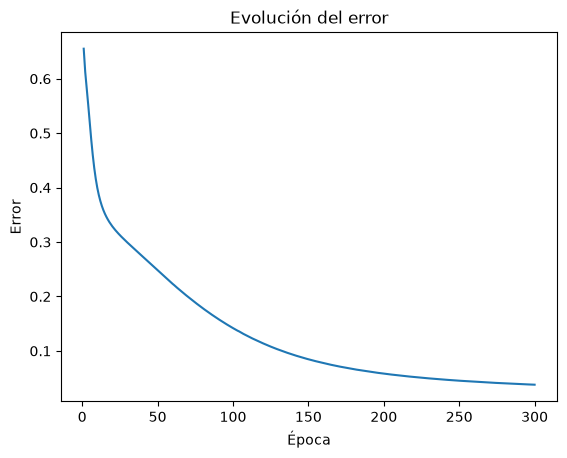

In [11]:
red.dibujar_error()

### **7.6. Evaluar la red**

Ahora sí, el examen: comprobamos cuántas flores acierta, tanto de las que ha usado para aprender como de las 30 que nunca ha visto.

In [12]:
print(f"Aciertos en entrenamiento: {red.exactitud(X_train, y_train):.0%}")
print(f"Aciertos en prueba:        {red.exactitud(X_test, y_test):.0%}")

Aciertos en entrenamiento: 99%
Aciertos en prueba:        90%


Si los aciertos en prueba son parecidos a los de entrenamiento, la red ha **generalizado**: ha aprendido algo que también sirve para flores nuevas.

Miremos con detalle algunas flores de prueba, con las salidas de las tres neuronas:

In [13]:
salidas = red.salida(X_test)
predicciones = red.predecir(X_test)

for i in range(8):
    real = especies[y_test[i]]
    predicha = especies[predicciones[i]]
    resultado = "✓" if real == predicha else "✗"
    print(f"{resultado} Real: {real:10s}  Predicha: {predicha:10s}  Salidas: {salidas[i].round(2)}")

✓ Real: setosa      Predicha: setosa      Salidas: [0.96 0.09 0.  ]
✓ Real: versicolor  Predicha: versicolor  Salidas: [0.07 0.84 0.01]
✓ Real: versicolor  Predicha: versicolor  Salidas: [0.03 0.85 0.05]
✓ Real: virginica   Predicha: virginica   Salidas: [0.   0.22 0.85]
✓ Real: virginica   Predicha: virginica   Salidas: [0.   0.1  0.94]
✓ Real: versicolor  Predicha: versicolor  Salidas: [0.01 0.88 0.1 ]
✗ Real: virginica   Predicha: versicolor  Salidas: [0.01 0.62 0.43]
✓ Real: setosa      Predicha: setosa      Salidas: [0.97 0.07 0.  ]


Fíjate en que, cuando la red acierta con seguridad, una de las salidas está cerca de 1 y las otras dos cerca de 0, como en la codificación *one-hot* de las etiquetas.

Para ver **en qué se equivoca**, contamos cuántas flores de cada especie real ha clasificado en cada especie. Esta tabla se llama **matriz de confusión**:

In [14]:
confusion = np.zeros((3, 3), dtype=int)
for real, predicha in zip(y_test, predicciones):
    confusion[real, predicha] += 1

print("Filas: especie real. Columnas: especie predicha.")
print(f"{'':12s}" + "".join(f"{e:>12s}" for e in especies))
for especie, fila in zip(especies, confusion):
    print(f"{especie:12s}" + "".join(f"{n:12d}" for n in fila))

Filas: especie real. Columnas: especie predicha.
                  setosa  versicolor   virginica
setosa                 9           0           0
versicolor             0          10           2
virginica              0           1           8


Los aciertos están en la diagonal. Los errores, si los hay, suelen estar entre *versicolor* y *virginica*, las dos especies más parecidas. La *setosa* es muy fácil de distinguir.

### **7.7. Clasificar una flor nueva**

Supongamos que medimos una flor en el campo. Para clasificarla hay que hacer con ella **lo mismo que con los datos de entrenamiento**: normalizarla con la **misma media y desviación**.

In [15]:
flor = np.array([[6.3, 2.9, 5.6, 1.8]])   # largo y ancho del sépalo, largo y ancho del pétalo

flor_normalizada = (flor - media) / desviacion

print("Salidas de la red:", red.salida(flor_normalizada).round(3))
print("Especie predicha: ", especies[red.predecir(flor_normalizada)[0]])

Salidas de la red: [[0.003 0.142 0.912]]
Especie predicha:  virginica


### **7.8. Experimenta**

Ahora te toca experimentar a ti. Cambia algo y vuelve a ejecutar las celdas desde la creación de la red (paso 4):

1. **Épocas:** prueba con `red.epocas = 20`. ¿Qué pasa con el error y con los aciertos? ¿Y con 1000?
2. **Neuronas ocultas:** prueba `NNet([4, 2, 3])` y `NNet([4, 20, 3])`.
3. **Más capas:** prueba `NNet([4, 8, 8, 3])`.
4. **Tasa de aprendizaje:** antes de entrenar, escribe `red.tasa_aprendizaje = 0.01` o `red.tasa_aprendizaje = 3`. ¿Qué ocurre con la curva del error?
5. **Tamaño del mini-batch:** prueba `red.tam_lote = 1` y `red.tam_lote = 120` (todas las flores a la vez).
6. **Sin normalizar:** salta el paso 3 y entrena con los datos originales. ¿Aprende igual de bien?

[← Notebook 5](05-perceptron-multicapa.ipynb)